# Lab 07: A First Machine Learning Species Distribution Model

## BIO597 Spatial Analysis of Biodiversity

Last week we built a suitability curve ourselves. This week we will use a **random forest** to learn a relationship between amphibian records and climate.

A decision tree asks a series of questions, such as “Is annual precipitation greater than 1,000 mm?” A random forest combines many trees. We will use `RandomForestRegressor` to produce a continuous suitability score.

We will:

* prepare presence and background data
* train a model and test its predictions
* make a suitability map and look at variable importance
* ask whether the model works in a different part of Maine
* explore unfamiliar environments and model uncertainty


## 1. Import packages

Most of these packages are familiar. `scikit-learn` adds tools for splitting data, fitting a random forest, and checking predictions.

Run this notebook from the `docs/labs` directory, as in earlier labs. If needed, install scikit-learn with `%pip install scikit-learn` in a new cell.


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split


## 2. Load the prepared data

The GeoJSON contains amphibian records and their climate values. The NetCDF contains climate layers for Maine. We do not need to download or clip rasters today.


In [2]:
amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

amphibians["species"].value_counts().head(12)


species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

## 3. Choose a species

We will use the wood frog, **Boreorana sylvatica**, again. Keep records with coordinate uncertainty below 100 m.


Number of records: 1198


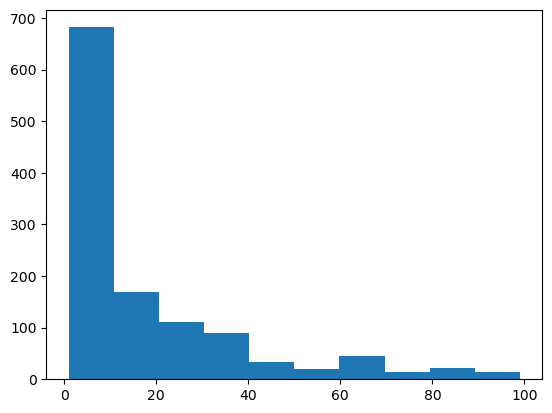

In [7]:
target_species = "Boreorana sylvatica"
presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

print("Number of records:", len(presence))

# Inspect the distribution of coordinate uncertainty
_ = plt.hist(presence["coordinateUncertaintyInMeters"])

## 4. Choose three climate predictors

A **predictor** is a variable we use to help predict the response. We will use:

* `bio_1`: annual mean temperature (°C)
* `bio_12`: annual precipitation (mm)
* `bio_15`: precipitation seasonality (variation in rainfall through the year)

These describe broad thermal and moisture conditions. They do not describe breeding ponds or forest cover.


In [8]:
features = ["bio_1", "bio_12", "bio_15"]

presence[features].head()


,bio_1,bio_12,bio_15
4,7.865667,1146.0,13.864340
12,6.616833,1088.0,10.415270
33,7.135167,1144.0,11.191950
38,6.411000,1080.0,10.817848
81,8.045667,1134.0,13.353818


## 5. Make a table of Maine's climate cells

Scikit-learn works with tables. Here, each row is one raster cell and each predictor gets its own column. Keep coordinates for mapping and remove cells with missing climate values.


In [14]:
grid = climate[features].to_dataframe().reset_index()
grid = grid[["x", "y"] + features]
grid = grid.dropna(subset=features)
grid.head()


,x,y,bio_1,bio_12,bio_15
146,-69.229167,47.437500,2.610167,1093.0,13.786905
147,-69.187500,47.437500,2.620167,1080.0,14.227962
148,-69.145833,47.437500,2.786333,1043.0,14.921009
246,-69.270833,47.395833,2.161333,1130.0,14.441315
247,-69.229167,47.395833,2.441500,1099.0,14.589335


## 6. Find which cells contain a presence

Use the nearest-cell selection we used last week to find the climate-cell center for each occurrence. `x` is longitude and `y` is latitude in these files.

Several records may fall in one cell. Keep only one copy of each cell so repeated observations do not enter both training and testing data. The matching code is provided; our focus today is the model.


In [15]:
point_x = xr.DataArray(presence.geometry.x.values, dims="record")
point_y = xr.DataArray(presence.geometry.y.values, dims="record")

presence["x"] = climate.x.sel(x=point_x, method="nearest").values
presence["y"] = climate.y.sel(y=point_y, method="nearest").values
presence_cells = presence[["x", "y"]].drop_duplicates().copy()
presence_cells["observed"] = 1


## 7. Add presence/background labels

Join the presence labels to the climate table using cell coordinates. Cells containing a record get **1**. Other cells get **0** and form our background pool.

**A background cell is not a confirmed absence.** It is a place without a record in this dataset. We are learning to distinguish recorded environments from background environments, not estimating abundance or the true probability of occurrence.


In [16]:
grid = grid.merge(presence_cells, on=["x", "y"], how="left")
grid["observed"] = grid["observed"].fillna(0)

presence_data = grid[grid["observed"] == 1].copy()
background_pool = grid[grid["observed"] == 0].copy()
print("Presence cells:", len(presence_data))


Presence cells: 450


## 8. Sample background cells

Use the same number of background cells as presence cells. `random_state` makes the random sample repeatable. The climate values for both groups come from the same raster table.


In [17]:
background = background_pool.sample(n=len(presence_data), random_state=597)
model_data = pd.concat([presence_data, background], ignore_index=True)

model_data["observed"].value_counts()


observed
1.0    450
0.0    450
Name: count, dtype: int64

## 9. Define predictors and response

In scikit-learn, **`X`** usually means the predictor table and **`y`** means the response we want to predict. Here, `y` contains our 1/0 presence/background labels. Coordinates stay out of the predictor table.


In [18]:
X = model_data[features]
y = model_data["observed"]

X.head()


,bio_1,bio_12,bio_15
0,3.028833,1013.0,16.424103
1,3.042667,999.0,17.518618
2,2.378000,1047.0,18.601431
3,2.878000,1095.0,19.441580
4,3.519167,939.0,20.804541


## 10. Set aside test data

A model can fit familiar data well and still predict new data poorly. We will use 75% of the cells to **train** the model and hold back 25% to **test** it.

`stratify=y` keeps similar proportions of presence and background in the two groups.


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=597, stratify=y,
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))


Training cells: 675
Test cells: 225


## 11. Train a random forest

`n_estimators=100` means 100 trees. `min_samples_leaf=5` prevents each tree from making its final groups too small. `.fit()` learns the relationship between climate and our labels.

Each tree predicts an average of its training labels. Averaging across trees gives a score between 0 and 1, which we will call **relative suitability**. Its meaning depends on how we chose the background data.


In [20]:
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=597,
)
model.fit(X_train, y_train)


,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",597
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease 

## 12. Predict the withheld cells

`.predict()` applies the learned relationship to a new predictor table. The model has not seen these cells' labels during training.

**Mean absolute error (MAE)** is the average distance between a predicted score and its assigned 0/1 label. Lower is better. For example, a score of 0.7 at a presence cell has an error of 0.3. For comparison, predicting 0.5 everywhere gives an MAE of 0.5. This checks our assigned labels, not actual occupancy.


Random-split MAE: 0.353


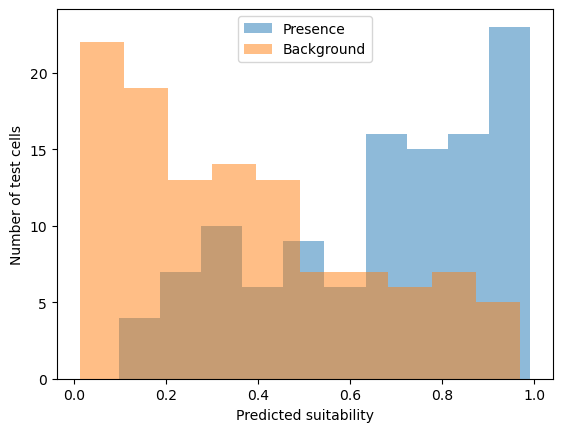

In [21]:
test_prediction = model.predict(X_test)
random_error = mean_absolute_error(y_test, test_prediction)
print("Random-split MAE:", round(random_error, 3))

plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.legend()
plt.show()


**Discuss:** Do held-out presence cells generally receive higher scores than background cells? Last week we checked a map against the records used to build it. Why is setting aside records a better test?

## 13. Make a suitability map

After testing, fit a final model with all our modeling cells and predict across Maine. The earlier test error belongs to the training/testing exercise; it is not a new test of this final model.


In [22]:
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
final_model.fit(X, y)
grid["suitability"] = final_model.predict(grid[features])


The following plotting recipe turns a table column back into a raster using its coordinates. `.reindex()` restores the original grid, including missing edge cells. You can reuse this recipe for other prediction columns.


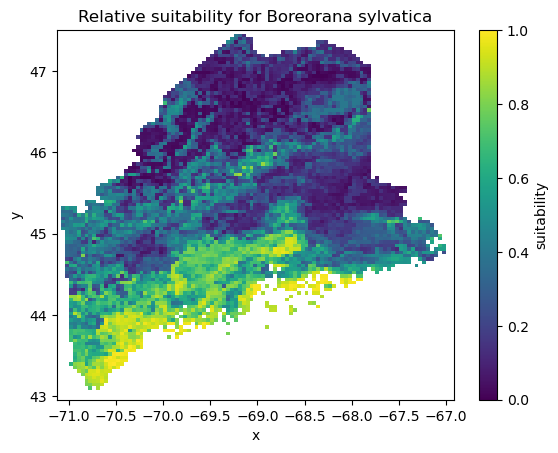

In [23]:
suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()


## 14. Which variables did the forest use most?

The forest provides a simple importance score for each predictor. Higher values mean a variable contributed more to reducing error during tree building. The scores sum to 1.

This describes how the model used its **training data**. It does not prove that a variable causes the species' distribution. Predictors containing similar information can share importance.


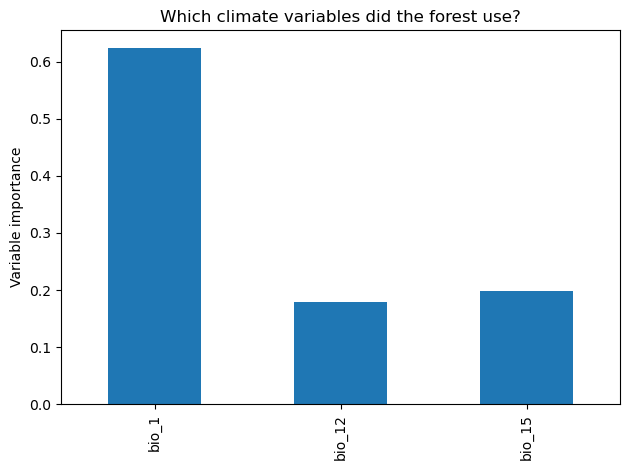

In [24]:
importance = pd.Series(final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()


## 15. A simple spatial cross-validation exercise

A random split can put neighboring cells in both training and testing groups. Nearby cells often have similar climate and sampling history, making prediction easier.

Instead, divide Maine at **45° latitude**. First train in the south and test in the north. Then reverse the roles. This is a simple two-fold spatial cross-validation: each region takes a turn as the withheld test area. Here, the table column `model_data["y"]` is latitude; the separate variable `y` above holds our response labels.


Points in the south: (503, 6)
Points in the nouth: (397, 6)


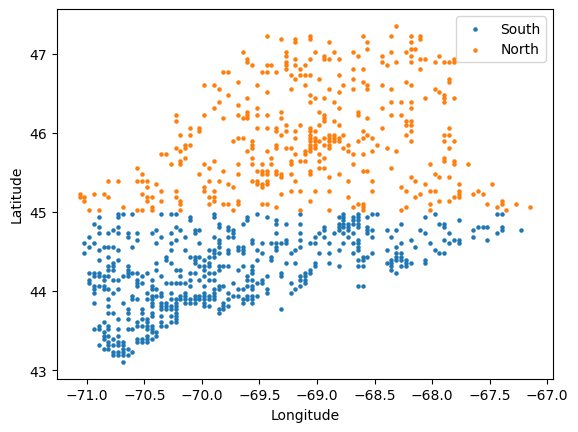

In [30]:
south = model_data[model_data["y"] < 45]
north = model_data[model_data["y"] >= 45]
print(f"Points in the south: {south.shape}")
print(f"Points in the nouth: {north.shape}")

plt.scatter(south["x"], south["y"], s=5, label="South")
plt.scatter(north["x"], north["y"], s=5, label="North")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


Train on southern cells and predict northern cells. Notice that the training and test predictor tables use the same columns in the same order.


In [31]:
south_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
south_model.fit(south[features], south["observed"])
north_prediction = south_model.predict(north[features])
north_error = mean_absolute_error(north["observed"], north_prediction)


Now train in the north and predict the south. We create a separate model so we can keep both fitted forests.


In [32]:
north_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
north_model.fit(north[features], north["observed"])
south_prediction = north_model.predict(south[features])
south_error = mean_absolute_error(south["observed"], south_prediction)

print("Random split:", round(random_error, 3))
print("Train south, test north:", round(north_error, 3))
print("Train north, test south:", round(south_error, 3))


Random split: 0.353
Train south, test north: 0.403
Train north, test south: 0.595


**Discuss:** Which test was hardest? The spatial models also use fewer training cells and different test environments, so geography is not the only difference. Cells near the dividing line can still be neighbors. More detailed spatial cross-validation can use multiple blocks and gaps between training and test areas.

## 16. Are we predicting unfamiliar temperatures?

A model trained in southern Maine may encounter temperatures in the north that it never saw during training. This is **environmental novelty**.

Find the southern training range for annual mean temperature, then map cells outside that range. The forest will still give these cells a score, but it has not learned how the species responds beyond its training temperatures.


Southern training temperature range: 2.632833242416382 to 8.609000205993652 °C


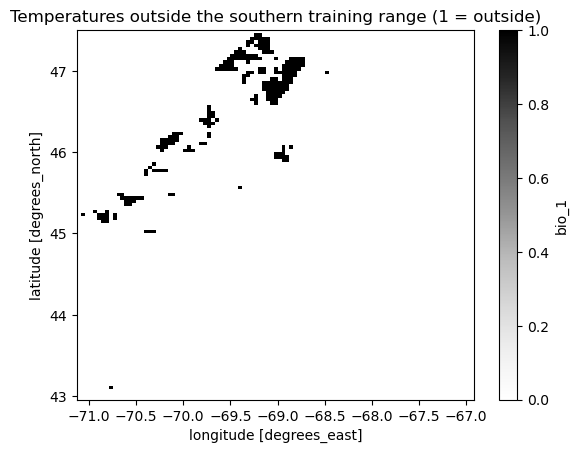

In [33]:
minimum_temp = south["bio_1"].min()
maximum_temp = south["bio_1"].max()
print("Southern training temperature range:", minimum_temp, "to", maximum_temp, "°C")

novel_temperature = (climate.bio_1 < minimum_temp) | (climate.bio_1 > maximum_temp)
novel_temperature = novel_temperature.where(climate.bio_1.notnull())
novel_temperature.plot(vmin=0, vmax=1, cmap="Greys")
plt.title("Temperatures outside the southern training range (1 = outside)")
plt.show()


**Discuss:** Where are temperatures unfamiliar to the southern model? This check uses only one variable. Familiar temperatures do not guarantee familiar rainfall, familiar combinations of conditions, or reliable predictions.

## 17. Do models trained in different regions agree?

Project the southern and northern models across Maine and calculate the absolute difference between their scores. Large differences show sensitivity to which region supplied the training data: one clue about **model uncertainty**.


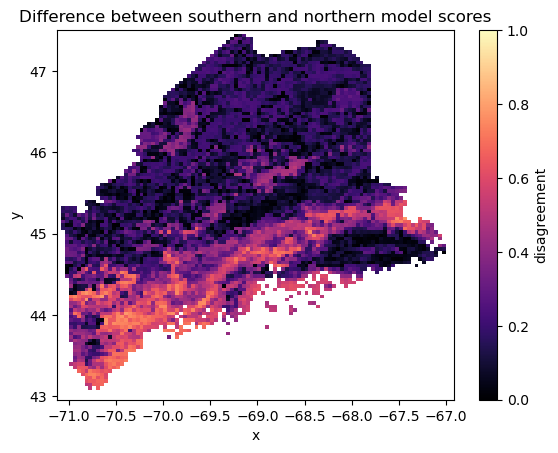

In [34]:
grid["south_score"] = south_model.predict(grid[features])
grid["north_score"] = north_model.predict(grid[features])
grid["disagreement"] = abs(grid["south_score"] - grid["north_score"])

disagreement = grid.set_index(["y", "x"])["disagreement"].to_xarray()
disagreement = disagreement.reindex(y=climate.y, x=climate.x)
disagreement.plot(vmin=0, vmax=1, cmap="magma")
plt.title("Difference between southern and northern model scores")
plt.show()


**Discuss:** Where do the models disagree? This map is not a confidence interval or a map of actual error. Both models can agree and still be wrong because of biased records or missing habitat information.

## 18. Save your suitability map

Use the same raster export method as last week. The supplied climate grid uses WGS84 longitude and latitude (`EPSG:4326`).


In [ ]:
suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Lab07_suitability.tif")


## Wrap-up

1. What do `.fit()` and `.predict()` do?
2. Why do we test a model on cells withheld from training?
3. What changed when we tested a different geographic region?
4. Why should we be cautious about unfamiliar environments and disagreement among models?
5. Why is our score not a probability that the species occurs at a location?

For the assignment, repeat this workflow for another species and explain the results in biological terms.

## References

* [Scikit-learn random forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)
* [WorldClim bioclimatic variables](https://www.worldclim.org/data/bioclim.html)
